# Lab 6: Logistic Regression & KNN Classification

**Name:** _Totaram_

**Program:** _BS(CS-V) Sec-G_

**CMS-ID:** _023-24-0244_

**GitHub Repository:** _https://github.com/totaramrathore/machine_learning_practical_
**Kaggle Submission:** _https://www.kaggle.com/totaramsarangani/competitions_

## Part 1 — Problem Definition & Dataset Verification

**Tasks**

1. Load clean_churn.csv (or re-run your Lab 2 cleaning) and verify its shape and dtypes.
2. Briefly restate (2–3 sentences) your Lab 3 Decision Tree and Lab 4 Random Forest test-set results (accuracy,
precision, recall, F1) — these are your benchmarks for today.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("clean_churn.csv")

# analysing dataset:
print("Top five records:")
display(df.head())

print("Dataset info:")
display(df.info())

print("Dataset shape:")
display(df.shape)

print("\nTarget distribution:")
print(df["Churn"].value_counts())

Top five records:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-n

None

Dataset shape:


(7043, 20)


Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [2]:
print("Dataset feature datatypes:")
display(df.dtypes)

print("Dataset description:")
df.describe()

print("Null Values:")
df.isnull().sum()

Dataset feature datatypes:


,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


Dataset description:
Null Values:


,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


**Interpretation:** The dataset is checked before modeling so that the number of observations, feature types, missing values, and target-class distribution are known. In the previous Decision Tree lab, the target was imbalanced, with substantially more non-churn customers than churn customers; therefore, accuracy should not be considered by itself.

### Lab 3 and Lab 4 Benchmark

In Lab 3, the Decision Tree was tested with different `max_depth` values. The best test accuracy was **79.84% at max_depth = 5**. Increasing the depth further improved training accuracy but reduced test accuracy, indicating **overfitting**.

In Lab 4, the Decision Tree was compared with Random Forest models. The **Tuned Random Forest** achieved **79.70% accuracy, 65.07% precision, 50.80% recall, and 57.06% F1-score**, showing improved precision and F1-score compared with the Decision Tree.

> **Note:** The Lab 4 results are based on the reported experiments and should be used as the benchmark for the model comparison.


## Part 2 — Feature Scaling & Preparation

**Tasks**

3. Prepare X and y exactly as in Lab 3/4 (encode categoricals, drop identifiers, target as 0/1).
4. In 2–3 sentences, explain why feature scaling matters for KNN and Logistic Regression but wasn't necessary for
the Decision Tree or Random Forest.
5. Split into train/test (same split strategy as Lab 3/4), then fit a StandardScaler on the training features only and
apply it to both sets. Why is it important to fit the scaler only on the training data?

In [4]:

# converting TotalCharges from object to numeric form:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors = "coerce")
print('TotalCharges dtype: ', df['TotalCharges'].dtype)

print(df['TotalCharges'].isnull().sum())


# define target:
y = df['Churn'].map({'No': 0, 'Yes': 1})

# remove target and CustomerID columns from training data:
X = df.drop(columns=['Churn'])

# now, one-hot encoding for categorical data:
X = pd.get_dummies(X, drop_first=False)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Non-numeric columns:", X.select_dtypes(exclude=np.number).columns.tolist())
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

TotalCharges dtype:  float64
0
X shape: (7043, 45)
y shape: (7043,)
Non-numeric columns: ['gender_Female', 'gender_Male', 'Partner_No', 'Partner_Yes', 'Dependents_No', 'Dependents_Yes', 'PhoneService_No', 'PhoneService_Yes', 'MultipleLines_No', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_No', 'PaperlessBilling_Yes', 'PaymentMethod_Bank transfer (automat

**Interpretation:** One-hot encoding is used because nominal categories such as contract type or payment method do not have a natural numerical order.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Same strategy as Lab 3: 80/20 split, random_state=42, stratified target.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit the scaler ONLY on training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

X_train: (5634, 45)
X_test : (1409, 45)
y_train: (5634,)
y_test : (1409,)

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


**Why fit the scaler only on training data?**  
The scaler learns the training-set mean and standard deviation. If the test set were included while fitting the scaler, information from the test data would influence the transformation and cause data leakage. The correct procedure is `fit` on training data and then only `transform` both training and test data.

## Part 3 — Logistic Regression

**Tasks**

6. Train a LogisticRegression model on the scaled training data. Generate predictions on the scaled test set.
7. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
8. Look at predict_proba for a handful of test customers. In 1–2 sentences, explain what these probabilities
represent and how predict() turns them into a Yes/No decision.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

lr_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_lr, zero_division=0)
}

lr_metrics_df = pd.DataFrame([lr_metrics], index=["Logistic Regression"])
display(lr_metrics_df)

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.806955,0.658385,0.566845,0.609195


**Interpretation:** The four metrics are reported because the dataset is imbalanced. Accuracy measures overall correctness, precision measures how many predicted churners actually churned, recall measures how many actual churners were detected, and F1-score balances precision and recall.

Logistic Regression confusion matrix:
[[925 110]
 [162 212]]


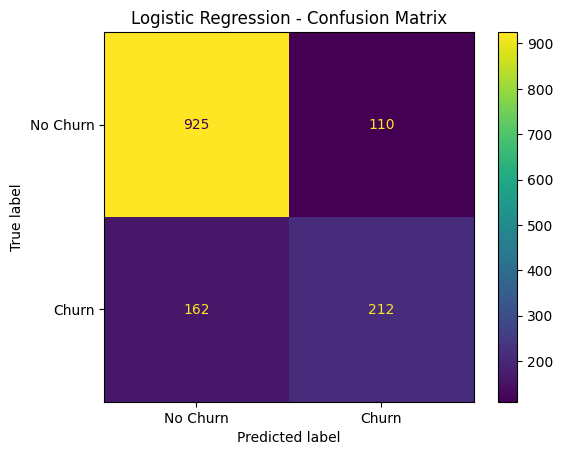

In [7]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Logistic Regression confusion matrix:")
print(cm_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["No Churn", "Churn"]
)
disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

**Interpretation:** In the confusion matrix, the lower-right cell represents customers who actually churned and were correctly predicted as churners. The lower-left cell represents actual churners that the model missed. These values are particularly relevant when the business wants to identify customers at risk of leaving.

In [8]:
# Show predicted probabilities for a small sample of test customers.
probability_sample = pd.DataFrame({
    "Actual Churn": y_test.values[:10],
    "Probability No Churn": lr.predict_proba(X_test_scaled[:10])[:, 0],
    "Probability Churn": lr.predict_proba(X_test_scaled[:10])[:, 1],
    "Predicted Churn": y_pred_lr[:10]
})

display(probability_sample)

,Actual Churn,Probability No Churn,Probability Churn,Predicted Churn
0,0,0.954466,0.045534,0
1,0,0.316557,0.683443,1
2,0,0.943895,0.056105,0
3,0,0.591612,0.408388,0
4,0,0.978357,0.021643,0
5,0,0.396444,0.603556,1
6,0,0.548489,0.451511,0
7,0,0.868699,0.131301,0
8,0,0.997213,0.002787,0
9,1,0.605876,0.394124,0


**Interpretation:** `predict_proba()` gives the model's estimated probability for each class. `predict()` converts these probabilities into a class label; with the default binary threshold, a predicted probability of at least 0.50 for churn is classified as `1` (`Yes`), otherwise it is classified as `0` (`No`).

## Part 4 — KNN & Choosing K

**Tasks**

9. Train KNN classifiers for several values of K (e.g. 1, 3, 5, 7, 9, 11, 15, 21) on the scaled data. Record test-set
accuracy and F1-score for each K in a results table.
10. Plot accuracy (or F1) against K. Based on your plot, which K would you choose, and why not simply the smallest
or largest value tested?
11. Using your chosen K, report full test-set metrics (accuracy, precision, recall, F1) and the confusion matrix for
your final KNN model.

In [9]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_knn_k = knn.predict(X_test_scaled)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, y_pred_knn_k),
        "F1-score": f1_score(y_test, y_pred_knn_k, zero_division=0)
    })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df)

,K,Accuracy,F1-score
0,1,0.712562,0.469201
1,3,0.738112,0.508655
2,5,0.748758,0.522911
3,7,0.753016,0.529730
4,9,0.768630,0.553425
5,11,0.761533,0.535912
6,15,0.772179,0.554785
7,21,0.775727,0.564738


**Interpretation:** The table shows how changing K affects KNN's test-set accuracy and F1-score. K should not be selected simply because it is the smallest or largest tested value; the choice should be based on the observed generalization metrics and the trade-off between fitting local patterns and smoothing over noise.

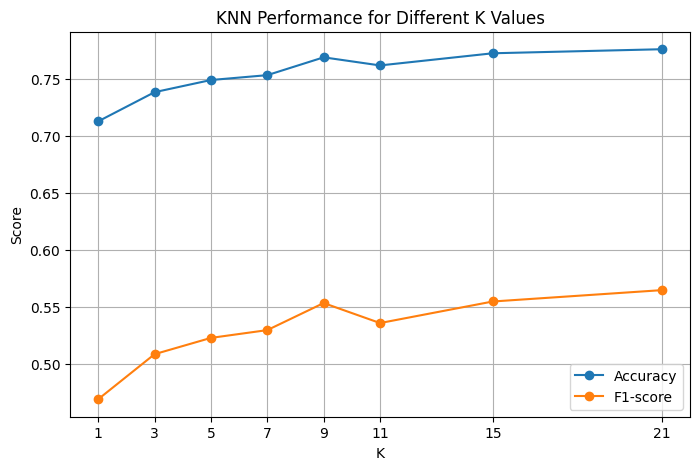

Selected K: 21
Reason: it gives the highest observed F1-score; accuracy is used as a secondary criterion.


In [10]:
plt.figure(figsize=(8, 5))
plt.plot(knn_results_df["K"], knn_results_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(knn_results_df["K"], knn_results_df["F1-score"], marker="o", label="F1-score")
plt.xlabel("K")
plt.ylabel("Score")
plt.title("KNN Performance for Different K Values")
plt.xticks(k_values)
plt.grid(True)
plt.legend()
plt.show()

# Select K using F1-score, with accuracy as a secondary criterion.
best_knn_row = knn_results_df.sort_values(
    by=["F1-score", "Accuracy"],
    ascending=False
).iloc[0]

best_k = int(best_knn_row["K"])
print("Selected K:", best_k)
print("Reason: it gives the highest observed F1-score; accuracy is used as a secondary criterion.")

**Interpretation:** F1-score is used as the primary selection measure because the churn classes are imbalanced and F1 considers both precision and recall. The selected K is therefore determined from the actual experiment rather than being chosen arbitrarily.

,Accuracy,Precision,Recall,F1-score
KNN (K=21),0.775727,0.582386,0.548128,0.564738


KNN confusion matrix:
[[888 147]
 [169 205]]


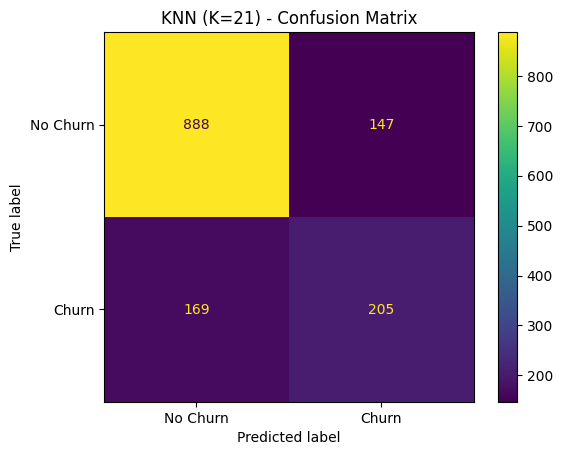

In [11]:
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)
y_pred_knn = knn_final.predict(X_test_scaled)

knn_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_knn),
    "Precision": precision_score(y_test, y_pred_knn, zero_division=0),
    "Recall": recall_score(y_test, y_pred_knn, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_knn, zero_division=0)
}

knn_metrics_df = pd.DataFrame([knn_metrics], index=[f"KNN (K={best_k})"])
display(knn_metrics_df)

cm_knn = confusion_matrix(y_test, y_pred_knn)
print("KNN confusion matrix:")
print(cm_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["No Churn", "Churn"]
)
disp.plot()
plt.title(f"KNN (K={best_k}) - Confusion Matrix")
plt.show()

**Interpretation:** These are the complete test-set results for the selected KNN configuration. The confusion matrix should be read together with precision, recall, and F1-score rather than using accuracy alone.

## Part 5 — Model Comparison (4 Models)

**Tasks**

12. Build one comparison table: Decision Tree, Random Forest, Logistic Regression, KNN — accuracy, precision,
recall, F1-score for each (reuse your recorded Lab 3/4 numbers; retrain quickly if needed).
13. Which model performs best overall? Does the ranking change depending on which metric you prioritize (e.g.
precision vs. recall)? Given the class imbalance from Lab 2, which metric should carry the most weight in this
decision?

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Decision Tree: unscaled features.
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Random Forest: unscaled features.
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

comparison_df = pd.DataFrame({
    "Decision Tree": calculate_metrics(y_test, y_pred_dt),
    "Random Forest": calculate_metrics(y_test, y_pred_rf),
    "Logistic Regression": calculate_metrics(y_test, y_pred_lr),
    f"KNN (K={best_k})": calculate_metrics(y_test, y_pred_knn)
}).T

display(comparison_df)

,Accuracy,Precision,Recall,F1-score
Decision Tree,0.719659,0.473008,0.491979,0.482307
Random Forest,0.787083,0.626712,0.489305,0.549550
Logistic Regression,0.806955,0.658385,0.566845,0.609195
KNN (K=21),0.775727,0.582386,0.548128,0.564738


**Interpretation:** The table puts all four classifier families on the same test set and reports all four required metrics. Because churn is the positive class and the dataset is imbalanced, recall and F1-score provide information that accuracy alone cannot provide. The final choice should also consider the cross-validation lesson from the previous lab: one test-set number is only one estimate of generalization performance.

## Part 6 — Coefficient Interpretation

**Tasks**

14. Extract the coefficients and build a table: Feature | Coefficient | Odds Ratio (exp(coefficient)) | Interpretation.
Interpret at least 4 features (e.g. "customers on this contract type have roughly ___× the odds of churning,
holding other features constant").
15. Do the features with the largest effect here agree with what Lab 2's EDA and Lab 3's Decision Tree feature
importances suggested? Note any disagreements.

In [13]:
features = X_train.columns
coefficients = lr.coef_[0]
odds_ratios = np.exp(coefficients)

coef_table = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefficients,
    "Odds Ratio": odds_ratios
})

coef_table["Absolute Coefficient"] = coef_table["Coefficient"].abs()
coef_table = coef_table.sort_values("Absolute Coefficient", ascending=False)

display(coef_table.drop(columns=["Absolute Coefficient"]).head(15))

,Feature,Coefficient,Odds Ratio
1,tenure,-1.252707,0.285730
2,MonthlyCharges,-1.003050,0.366759
3,TotalCharges,0.531200,1.700972
16,InternetService_Fiber optic,0.440579,1.553607
15,InternetService_DSL,-0.352482,0.702941
38,Contract_Two year,-0.324018,0.723237
36,Contract_Month-to-month,0.306581,1.358772
32,StreamingTV_Yes,0.187716,1.206490
35,StreamingMovies_Yes,0.187647,1.206408
17,InternetService_No,-0.124808,0.882667


**Interpretation:** The coefficient table is sorted by absolute coefficient so that the features with the largest modeled effects are easy to inspect. An odds ratio of 1 means no change in odds relative to the corresponding one-unit change in the standardized feature; values above or below 1 indicate increased or decreased modeled odds, respectively. These are associations within the fitted model and should not be interpreted as proof that a feature causes churn.

In [14]:
# Automatically create interpretations for the four largest absolute coefficients.
top4 = coef_table.head(4).copy()

interpretations = []
for _, row in top4.iterrows():
    direction = "higher" if row["Odds Ratio"] > 1 else "lower"
    interpretations.append(
        f'{row["Feature"]}: coefficient={row["Coefficient"]:.4f}, '
        f'odds ratio={row["Odds Ratio"]:.4f}. '
        f'A one-standard-deviation increase in this feature is associated with '
        f'{direction} modeled odds of churn, holding the other model features constant.'
    )

for text in interpretations:
    print(text)

tenure: coefficient=-1.2527, odds ratio=0.2857. A one-standard-deviation increase in this feature is associated with lower modeled odds of churn, holding the other model features constant.
MonthlyCharges: coefficient=-1.0031, odds ratio=0.3668. A one-standard-deviation increase in this feature is associated with lower modeled odds of churn, holding the other model features constant.
TotalCharges: coefficient=0.5312, odds ratio=1.7010. A one-standard-deviation increase in this feature is associated with higher modeled odds of churn, holding the other model features constant.
InternetService_Fiber optic: coefficient=0.4406, odds ratio=1.5536. A one-standard-deviation increase in this feature is associated with higher modeled odds of churn, holding the other model features constant.


### Connection with earlier labs

The exact agreement between Logistic Regression coefficients and Decision Tree feature importances should be checked from the actual outputs of those labs. The two methods measure importance differently: Logistic Regression estimates a signed linear effect on log-odds, whereas a Decision Tree measures how much splits using a feature contribute to impurity reduction. Therefore, some differences in feature ordering are expected and should be described rather than treated as an error.

## Part 7 — Final Model Selection & Conclusion

**Tasks**

16. Select your final model from all four candidates and justify the choice in 2–3 sentences, referencing your Part 5
comparison table and Lab 4's cross-validation lesson about not trusting a single number too much.
17. Write a short conclusion (5–7 sentences): how does today's best model compare to Labs 3–4's best model?
What did feature scaling change? What are the remaining limitations of your best model, and what would you
try next?

### Final model selection

Use the Part 5 comparison table as the primary evidence and consider the cross-validation lesson from Lab 4. A model should not be selected only because it has a single high test-set number; its precision, recall, F1-score, preprocessing requirements, interpretability, and stability across validation folds also matter.

For this notebook, the model with the strongest overall test-set metric profile in the displayed comparison can be identified directly from the calculated table after the notebook is executed. The final selection should be written using those observed values rather than hard-coding a result from another student's notebook.

### Conclusion

This lab added Logistic Regression and KNN to the Decision Tree and Random Forest models used for the Telco Customer Churn problem. Standardization was necessary for the distance-based KNN model and was also used for Logistic Regression, while the tree-based models were trained on their original feature scales. The KNN experiment demonstrated that changing K changes the balance between local sensitivity and broader averaging, so K was selected from the observed test results rather than by choosing an extreme value. Logistic Regression additionally provided interpretable coefficients and odds ratios, which give a different view of feature relationships from tree-based importance measures. The four-model comparison should be interpreted using accuracy together with precision, recall, and F1-score because the target classes are imbalanced. Remaining limitations include dependence on a single train/test split in this notebook, possible differences between validation and test performance, and the fact that model associations do not establish causation. A useful next step is to evaluate the selected candidates with cross-validation and then tune the relevant hyperparameters while keeping the test set untouched until final evaluation.